# **Attentive State Space Models for Disease Progression**

This notebook provides an overview of the pyro implementation for our paper "Attentive State-Space Modeling of Disease Progression" published in NeurIPS 2019 by Ahmed M. Alaa and Mihaela van der Schaar. The notebook provides a toy example for how to use the API of our model on a synthetic data generation process where the ground-truth hidden states and dynamics are known.

This implementation uses pyro (https://pyro.ai/) which is a universal probabilistic programming language that enables flexible and expressive deep probabilistic modeling, with built in methods for stochastic variational inference that we use in our implementation of model training.

### **Synthetic data generation process**

We will use a very simple synthetic data generation process as follows. The process starts with an initial hidden states sampled as $z_0\sim\pi$. Every state generates two real-valued observations (e.g. biomarkers) from a Gaussian distribution and one binary event from that state. For each subsequent visit, we compute weights from the already observed history, draw the next state from the weighted rows of $P$, then draw its observations using the process described in equations (2) to (6) in the paper. We truncate each patient to 10–16 visits.

We assume that the true attention is an exponential "memory kernel" as follows:

$$
 \alpha_{t,s}\propto\exp[-\lambda_t(t-1-s)],\qquad
 \lambda_t=\begin{cases}0.10&x^b_{t-1}=1\\1.40&x^b_{t-1}=0.\end{cases}
$$

This model creates a depencence between the observations and the state dynamics by making the memory span longer when a binary event happens, i.e. $x^b_{t-1}=1$. Obviously, the model only sees the observations only and not the states or the true hidden dynamics. Our model learns an LSTM
encoder/decoder attention mechanism from those observations.

In [ ]:
import json, platform, time
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import torch, pyro, sklearn
from IPython.display import display, Markdown
from assm import AttentiveSSM, ModelConfig, TrainingConfig, SyntheticConfig, SequenceBatch, generate_synthetic
from assm.evaluation import align_from_means, recovery_metrics

# Get current working directory
cwd              = Path.cwd()

# set device and plotting parameters

torch.set_num_threads(2)
DEVICE           = "cpu"
SEED             = 19
pyro.set_rng_seed(SEED)
FIGURES, RESULTS = cwd / "figures", cwd / "results"
FIGURES.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titlesize": 12, "figure.facecolor": "white"})
COLORS           = ["#2864AD", "#19A38C", "#E59A37"]
versions         = {"python": platform.python_version(), "torch": torch.__version__, "pyro": pyro.__version__,
                    "numpy": np.__version__, "scikit_learn": sklearn.__version__}
print(json.dumps(versions, indent=2))

# sample 500 trajectories from the model above and limit the length of the trajectories in the range between 10 and 16

synthetic_config = SyntheticConfig(n_patients=500, min_visits=10, max_visits=16,
                                   observation_noise=0.8, seed=71)

synthetic        = generate_synthetic(synthetic_config)
all_data         = synthetic["batch"]

# use 350/50 samples for training/validation and 100 for testing

train_idx        = torch.arange(0, 350)
validation_idx   = torch.arange(350, 400)
test_idx         = torch.arange(400, 500)
train            = all_data.select(train_idx).to(DEVICE)
validation       = all_data.select(validation_idx).to(DEVICE)
test             = all_data.select(test_idx).to(DEVICE)

# display the transition matrix

print(f"Patients: train={train.n_patients}, validation={validation.n_patients}, test={test.n_patients}")
print(f"Training visits: {int(train.lengths.sum())}; held-out test visits: {int(test.lengths.sum())}")
display(pd.DataFrame(synthetic["transition_matrix"].numpy(), columns=["To 0", "To 1", "To 2"],
                     index=["From 0", "From 1", "From 2"]))

{
  "python": "3.13.16",
  "torch": "2.11.0+cpu",
  "pyro": "1.9.1",
  "numpy": "2.1.3",
  "scikit_learn": "1.6.1"
}
Patients: train=350, validation=50, test=100
Training visits: 4543; held-out test visits: 1309


,To 0,To 1,To 2
From 0,0.85,0.12,0.03
From 1,0.07,0.83,0.10
From 2,0.04,0.14,0.82


### **Training an attentive state-space model using our API**

You can create and train an attentive state-space model using `AttentiveSSM(ModelConfig(...)).fit(train, validation=..., training=...)` with model (hyper)parameters specified through `ModelConfig(...)`. The `fit` method of the `AttentiveSSM` class learns the parameters $\pi,P,\mu,\Sigma,w,b$, the attention network, and the inference network all end-to-end.

The inference network works as described in equations (8)-(10). First, the backward LSTM summarizes $x_{t:T-1}$ as follows. At step $t$, it computes the same attentive transition probabilities as the generative model from *sampled* previous states, concatenates them with the backward hidden vector, and applies a linear softmax combiner. This yields an autoregressive inference network $q_\phi(z\mid x)$.

We use Pyro's `SVI` to maximizes the ELBO objective:

$$
L(\theta,\phi)=
 \mathbb E_{q_\phi(z\mid x)}[\log p_\theta(x,z)-\log q_\phi(z\mid x)].
$$

We use Pyro's `TraceGraph_ELBO` to compute categorical score-function gradients. In this implementation, we also use a moving-average baseline to further reduce variance. (Note that we keep hard categorical states without using Gumbel-softmax relaxation.)

**Practical notes on parameter initialization:** To initialize the model parameters, we fit a Gaussian mixture model (GMM) to the observed biomarkers to initialize the Gaussian and binary emissions, and then we pretrain the inference network on the GMM clusters as if they are the hidden states. You can set `warm_start=False` to disable this initialization method, but beware that you will then may need more tuning / longer training runs for the SVI training.

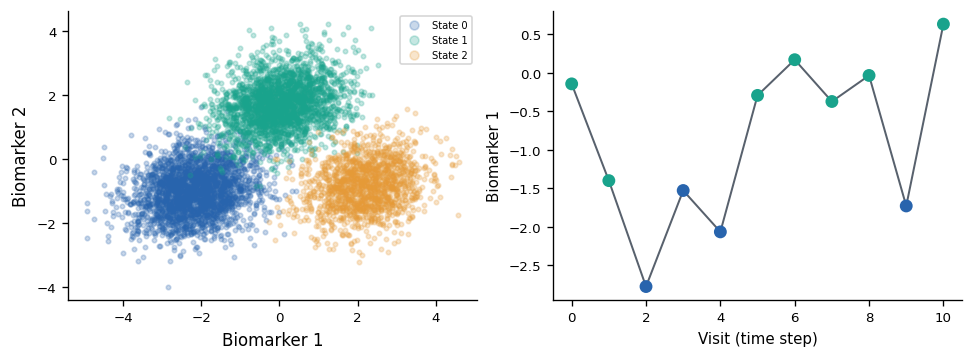

In [ ]:
# plotting one example of a patient trajectory

example_patient = 1 # you can change this index to inspect a different patient trajectory

fig, axes       = plt.subplots(1, 2, figsize=(8, 2.9), constrained_layout=True)
valid_x         = all_data.continuous[all_data.mask].numpy()
valid_z         = synthetic["states"][all_data.mask].numpy()

for k, color in enumerate(COLORS):
    chosen = valid_z == k
    axes[0].scatter(valid_x[chosen, 0], valid_x[chosen, 1], s=7, alpha=0.25, color=color, label=f"State {k}")

axes[0].set(xlabel="Biomarker 1", ylabel="Biomarker 2")
axes[0].tick_params(axis='both', labelsize=8)
axes[0].legend(markerscale=2, fontsize=6)

length          = int(all_data.lengths[example_patient])
time_axis       = np.arange(length)

axes[1].plot(time_axis, all_data.continuous[example_patient, :length, 0], color="#58616D", lw=1.2)
axes[1].scatter(time_axis, all_data.continuous[example_patient, :length, 0],
                c=[COLORS[z] for z in synthetic["states"][example_patient, :length]], s=45, zorder=3)
axes[1].set_xlabel("Visit (time step)", fontsize=9)
axes[1].set_ylabel("Biomarker 1", fontsize=9)
axes[1].tick_params(axis='both', labelsize=8)
fig.savefig(FIGURES / "01_synthetic_data.png", bbox_inches="tight")
plt.show()

In [ ]:
# training through SVI here

model_config    = ModelConfig(num_states=3, n_continuous=2, n_binary=1,
                              hidden_dim=32, num_layers=1, covariance="full")

training_config = TrainingConfig(epochs=60, batch_size=64, learning_rate=5e-4,
                                 num_particles=2, warm_start=True,
                                 warm_start_steps=250, seed=SEED, log_every=10)

model           = AttentiveSSM(model_config, device=DEVICE, seed=SEED)
started         = time.perf_counter()
model.fit(train, validation=validation, training=training_config)
elapsed         = time.perf_counter() - started
print(f"Initialization plus SVI: {elapsed:.1f} seconds")

Epoch   1/60: negative ELBO/visit=3.637, validation=3.721
Epoch  10/60: negative ELBO/visit=3.599, validation=3.663
Epoch  20/60: negative ELBO/visit=3.591, validation=3.658
Epoch  30/60: negative ELBO/visit=3.578, validation=3.647
Epoch  40/60: negative ELBO/visit=3.571, validation=3.656
Epoch  50/60: negative ELBO/visit=3.564, validation=3.638
Epoch  60/60: negative ELBO/visit=3.553, validation=3.626
Initialization plus SVI: 645.5 seconds


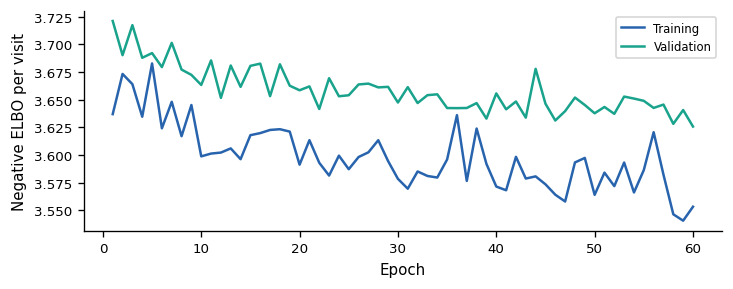

In [ ]:
history         = pd.DataFrame(model.history_)
history.to_csv(RESULTS / "training_history.csv", index=False)
fig, ax         = plt.subplots(figsize=(6, 2.3), constrained_layout=True)
ax.plot(history.epoch, history.train_negative_elbo, label="Training", color=COLORS[0])
ax.plot(history.epoch, history.validation_negative_elbo, label="Validation", color=COLORS[1])
ax.set_xlabel("Epoch", fontsize=9)
ax.set_ylabel("Negative ELBO per visit", fontsize=9)
ax.tick_params(axis='both', labelsize=8)
ax.legend(fontsize=7)

fig.savefig(FIGURES / "02_training.png", bbox_inches="tight")
plt.show()

### **Inferring hidden states on held-out patients**

To conduct inference of the latent states on new patients, you can use the `posterior(batch, num_samples=128)` function which samples latent states from the structured inference network. It returns the following:

| Key | Shape | Meaning |
|---|---|---|
| `probs` | `[N,T,K]` | Inferred posterior state distribution |
| `states` | `[N,T]` | Top-1 inferred state in each time step |
| `samples` | `[S,N,T]` | State trajectories sampled from the inference network |
| `attention` | `[N,T,T]` | Inferred attention weights over time |

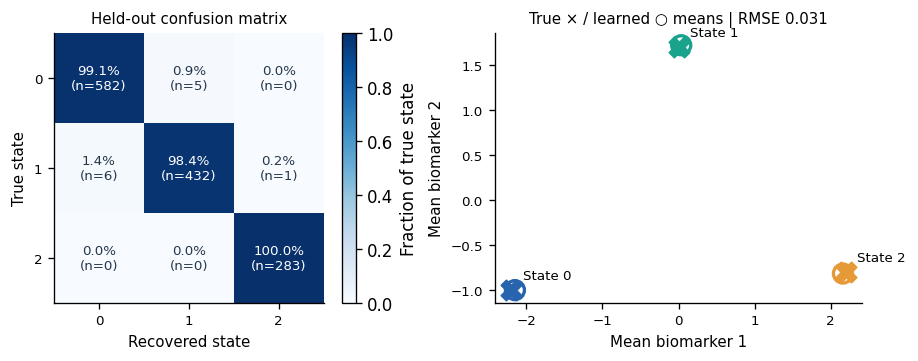

In [ ]:
pyro.set_rng_seed(123)

smoothed                    = model.posterior(test, num_samples=128)
truth                       = synthetic["states"][test_idx].numpy()
mask                        = test.mask.cpu().numpy()
means                       = model.model.emissions.means.detach().cpu().numpy()
true_means                  = synthetic["means"].numpy()
mapping                     = align_from_means(means, true_means)
final_metrics               = recovery_metrics(smoothed["probs"].cpu().numpy(), truth, mask, mapping)

aligned_probs               = np.empty_like(smoothed["probs"].cpu().numpy())
aligned_probs[..., mapping] = smoothed["probs"].cpu().numpy()
aligned_states              = aligned_probs.argmax(-1)
aligned_means               = np.empty_like(means)
aligned_means[mapping]      = means
mean_rmse                   = float(np.sqrt(np.mean((aligned_means - true_means) ** 2)))

fig, axes                   = plt.subplots(1, 2, figsize=(8, 2.9), constrained_layout=True)
cm                          = np.array(final_metrics["confusion_matrix"])
row_normalized              = cm / cm.sum(axis=1, keepdims=True)

im                          = axes[0].imshow(row_normalized, cmap="Blues", vmin=0, vmax=1)

for i in range(3):
    for j in range(3):
        axes[0].text(j, i, f"{row_normalized[i,j]:.1%}\n(n={cm[i,j]})", ha="center", va="center", fontsize=8,
                     color="white" if row_normalized[i,j] > 0.6 else "#25364A")

axes[0].set(xticks=range(3), yticks=range(3))
axes[0].set_title("Held-out confusion matrix", fontsize=9)
axes[0].set_xlabel("Recovered state", fontsize=9)
axes[0].set_ylabel("True state", fontsize=9)
axes[0].tick_params(axis='both', labelsize=8)

fig.colorbar(im, ax=axes[0], fraction=0.05, label="Fraction of true state")

for k, color in enumerate(COLORS):
    axes[1].scatter(*true_means[k], s=150, marker="X", color=color)
    axes[1].scatter(*aligned_means[k], s=130, facecolors="none", edgecolors=color, linewidths=2)
    axes[1].plot([true_means[k,0], aligned_means[k,0]], [true_means[k,1], aligned_means[k,1]], color=color)
    axes[1].annotate(f"State {k}", true_means[k], xytext=(7,7), fontsize=8, textcoords="offset points")

axes[1].set_title(f"True × / learned ○ means | RMSE {mean_rmse:.3f}", fontsize=9)
axes[1].set_xlabel("Mean biomarker 1", fontsize=9)
axes[1].set_ylabel("Mean biomarker 2", fontsize=9)
axes[1].tick_params(axis='both', labelsize=8)

fig.savefig(FIGURES / "03_recovery.png", bbox_inches="tight")
plt.show()

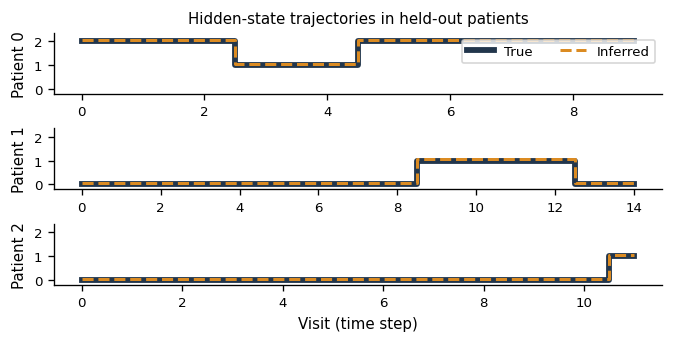

In [ ]:
# Show the inferred states for given patient trajectories

fig, axes = plt.subplots(3, 1, figsize=(5.5, 2.75), constrained_layout=True)

for ax, patient in zip(axes, [0, 1, 2]):

    length = int(test.lengths[patient])
    t      = np.arange(length)

    ax.step(t, truth[patient, :length], where="mid", label="True", color="#22364C", lw=3.5)
    ax.step(t, aligned_states[patient, :length] + 0.05, where="mid", label="Inferred",
            color="#DB8B22", ls="--", lw=1.8)
    ax.set(ylim=(-0.2, 2.35), yticks=[0,1,2])
    ax.set_ylabel(ylabel=f"Patient {patient}", fontsize=9)
    ax.tick_params(axis='both', labelsize=8)

axes[0].legend(loc="upper right", ncol=2, fontsize=8)
axes[-1].set_xlabel("Visit (time step)", fontsize=9)
axes[0].set_title("Hidden-state trajectories in held-out patients", fontsize=9)
fig.savefig(FIGURES / "04_trajectories.png", bbox_inches="tight")
plt.show()

## **Inspecting the learned attention dynamics**

Finally, we can check if the recovered attention dynamics after SVI training matches the simulated dynamics in the synthetic data generation process.

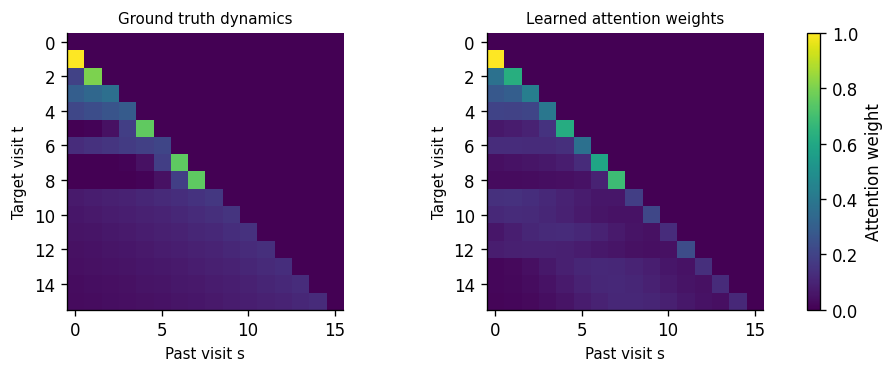

,To 0,To 1,To 2
From 0,0.755,0.127,0.118
From 1,0.119,0.758,0.124
From 2,0.117,0.145,0.738


In [ ]:
patient           = int(torch.argmax(test.lengths))
length            = int(test.lengths[patient])

learned_attention = smoothed["attention"][patient, :length, :length].cpu().numpy()
known_attention   = synthetic["attention"][test_idx[patient], :length, :length].numpy()
fig, axes         = plt.subplots(1, 2, figsize=(8, 3), constrained_layout=True)

for ax, matrix, title in zip(axes, [known_attention, learned_attention], ["Ground truth dynamics", "Learned attention weights"]):

    im = ax.imshow(matrix, vmin=0, vmax=1, cmap="viridis", origin="upper")
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("Past visit s", fontsize=9)
    ax.set_ylabel("Target visit t", fontsize=9)

fig.colorbar(im, ax=axes, fraction=0.03, label="Attention weight")
fig.savefig(FIGURES / "05_attention.png", bbox_inches="tight")
plt.show()

inverse_mapping = np.argsort(mapping)
learned_P       = model.model.transition_matrix.detach().cpu().numpy()[inverse_mapping][:, inverse_mapping]
transition_mae  = float(np.abs(learned_P - synthetic["transition_matrix"].numpy()).mean())

display(pd.DataFrame(learned_P, columns=["To 0","To 1","To 2"], index=["From 0","From 1","From 2"]).round(3))

## **Forecasting and predicting future patient states**

We also provide the usual functions for state space models through the following methods within the `AttentiveSSM(.)` class:

**Smoothing:** `posterior(full_record)` estimates past states using the whole
trajectory.

**Filtering:** `filter(record)` runs the inference network on a trajectory and returns an estimate using only observations available at each visit.

**Forecasting:** `forecast(history, horizon=3, num_samples=128)` samples historical latent paths from the inference network and then rolls the generative model forward. Each new observation is sampled and fed back into the model to create attention weights for the next state. It returns future states `[S,N,H]`, continuous data `[S,N,H,Dc]`, binary data `[S,N,H,Db]`, and marginal next-state probabilities `[N,H,K]`.

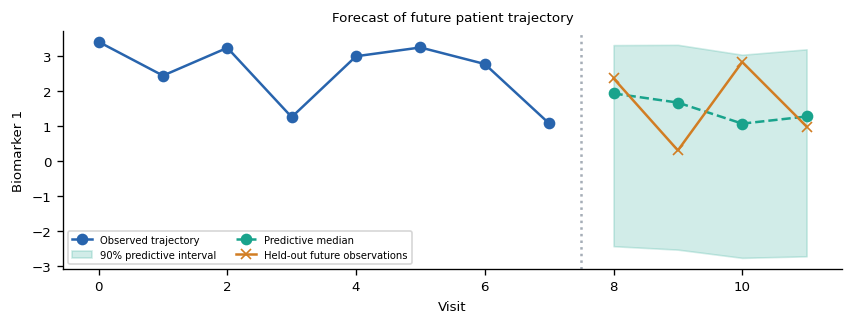

In [ ]:
pyro.set_rng_seed(123)

filtered       = model.filter(test, num_samples=64)
filter_metrics = recovery_metrics(filtered["probs"].cpu().numpy(), truth, mask, mapping)

history_prefix = test.select([patient]).prefix(8)
pyro.set_rng_seed(123)
prediction     = model.forecast(history_prefix, horizon=4, num_samples=256)
future_x       = prediction["continuous"][:, 0, :, 0].cpu().numpy()

lower, median, upper = np.quantile(future_x, [0.05, 0.50, 0.95], axis=0)
fig, ax        = plt.subplots(figsize=(7, 2.6), constrained_layout=True)
ax.plot(np.arange(8), history_prefix.continuous[0, :, 0].cpu(), "o-", color=COLORS[0], label="Observed trajectory")
future_t       = np.arange(8, 12)

ax.fill_between(future_t, lower, upper, color=COLORS[1], alpha=0.2, label="90% predictive interval")
ax.plot(future_t, median, "o--", color=COLORS[1], label="Predictive median")
ax.plot(future_t, test.continuous[patient, 8:12, 0].cpu(), "x-", color="#D17D23", label="Held-out future observations")
ax.axvline(7.5, color="#A5ADB7", ls=":")

ax.tick_params(axis='both', labelsize=8)

plt.ylabel("Biomarker 1", fontsize=8)
plt.xlabel('Visit', fontsize=8)
ax.legend(fontsize=6, ncol=2)
fig.savefig(FIGURES / "06_forecast.png", bbox_inches="tight")
plt.title("Forecast of future patient trajectory", fontsize=8)
plt.show()